# PointNet Model

**Authors:** Florian Klaver, Nicola Noger

In this Notebook the final version of the PointNet Model is developed and deployed

---

## Setup

In [85]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import laspy
import joblib
import json
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# Seeds for reproducibility 
np.random.seed(42)
tf.random.set_seed(42)

---

## Preprocessing

In this section the training and validation data is loaded and preprocessed

In [54]:
# -- Important parameters --
FOLDER_PATH = "C:/Users/flori/Desktop/pa-1_data/training" # Path containing the .laz files for training
N_POINTS    = 1024
BLOCK_SIZE  = 50.0     # 50 m tiles
STRIDE      = 25.0     # 50% overlap between the tiles
BATCH_SIZE  = 64

In [55]:
# -- Locate and sort LAZ files --
file_paths = sorted(glob.glob(os.path.join(FOLDER_PATH, "*.laz")))
print(f"Found {len(file_paths)} files for preprocessing.")

# -- Build global label map (excluding class 7) --
all_raw_labels = []
for path in file_paths:
    las = laspy.read(path)
    all_raw_labels.extend(np.unique(las.classification))
unique_labels = np.unique(all_raw_labels)
unique_labels = unique_labels[unique_labels != 7]                    # Exclude class 7
label_map = {int(raw): idx for idx, raw in enumerate(unique_labels)} # Map raw labels to indices
NUM_CLASSES = len(label_map)
print("Label map:", label_map)

# -- Tiling function with overlap --
def tile_pointclouds(
    X_all, y_all, coords_all,
    n_points=N_POINTS,
    block_size=BLOCK_SIZE,
    stride=STRIDE,
    padding=True
):
    """
    Tile point clouds into blocks of a given size with a specified stride.
    Args:
        X_all: Array of point cloud features.
        y_all: Array of point cloud labels.
        coords_all: Array of point cloud coordinates.
        n_points: Number of points per block (None for no limit).
        block_size: Size of each block.
        stride: Stride for tiling.
        padding: Whether to pad blocks with fewer points.
    Returns:
        X_list: List of blocks of point cloud features.
        y_list: List of blocks of point cloud labels.
    """

    x_min, y_min = coords_all[:,0].min(), coords_all[:,1].min()
    x_max, y_max = coords_all[:,0].max(), coords_all[:,1].max()

    x_edges = np.arange(x_min, x_max, stride)
    y_edges = np.arange(y_min, y_max, stride)

    X_list, y_list = [], []
    for xi in x_edges:
        for yi in y_edges:
            mask = (
                (coords_all[:,0] >= xi) & (coords_all[:,0] < xi + block_size) &
                (coords_all[:,1] >= yi) & (coords_all[:,1] < yi + block_size)
            )
            idx = np.where(mask)[0]
            if len(idx) == 0:
                continue

            if n_points is not None:
                if len(idx) >= n_points:
                    chosen = np.random.choice(idx, n_points, replace=False)
                else:
                    if not padding:
                        continue
                    pad_idx = np.random.choice(idx, n_points - len(idx), replace=True)
                    chosen = np.concatenate([idx, pad_idx])
            else:
                chosen = idx

            X_list.append(X_all[chosen])
            y_list.append(y_all[chosen])

    if not X_list:
        raise ValueError("No blocks found; check your stride/block_size.")

    return np.stack(X_list), np.stack(y_list)

Found 20 files for preprocessing.
Label map: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 15: 6, 17: 7}


In [56]:
# -- Preprocess all files into blocks --
all_X_blocks, all_y_blocks = [], []
for path in file_paths:
    las = laspy.read(path)
    raw_labels = las.classification.astype(int)

    # Feature extraction
    ground_z = np.min(las.z)
    X = np.vstack([
        las.x, las.y, las.z,
        las.intensity,
        las.return_number,
        las.number_of_returns,
        las.z - ground_z,
        las.scan_angle
    ]).T.astype(np.float32)

    # Mask & map labels
    mask = (raw_labels != 7)
    X = X[mask]
    y = np.array([label_map[int(r)] for r in raw_labels[mask]], dtype=np.int32)

    # Tile into overlapping blocks
    coords = X[:, :2]
    X_blocks, y_blocks = tile_pointclouds(X, y, coords, padding=True)

    # Center each block
    for b in range(X_blocks.shape[0]):
        cent = X_blocks[b, :, :3].mean(axis=0)
        X_blocks[b, :, :3] -= cent

    all_X_blocks.append(X_blocks)
    all_y_blocks.append(y_blocks)
    print(f"  {os.path.basename(path)} → {X_blocks.shape[0]} blocks")

# Concatenate
X_pointcloud = np.concatenate(all_X_blocks, axis=0)
y_pointcloud = np.concatenate(all_y_blocks, axis=0)
print("Total blocks:", X_pointcloud.shape[0])

  2671500_1251000.laz → 400 blocks
  2671500_1252000.laz → 400 blocks
  2672000_1251000.laz → 400 blocks
  2672500_1252000.laz → 400 blocks
  2673000_1251500.laz → 400 blocks
  2673000_1252000.laz → 400 blocks
  2679500_1248500.laz → 400 blocks
  2679500_1249500.laz → 400 blocks
  2680000_1249000.laz → 400 blocks
  2680500_1249500.laz → 400 blocks
  2687000_1250000.laz → 400 blocks
  2687000_1251000.laz → 400 blocks
  2687500_1251000.laz → 400 blocks
  2688000_1251000.laz → 400 blocks
  2696000_1245000.laz → 400 blocks
  2696000_1245500.laz → 400 blocks
  2696500_1245000.laz → 400 blocks
  2696500_1245500.laz → 400 blocks
  2697000_1261500.laz → 400 blocks
  2697000_1262000.laz → 400 blocks
Total blocks: 8000


In [57]:
# -- Fit a single scaler on all non-spatial features --
non_sp = X_pointcloud[:, :, 3:].reshape(-1, X_pointcloud.shape[2]-3)
scaler = StandardScaler().fit(non_sp)
M, P, F = X_pointcloud.shape
X_pointcloud[:, :, 3:] = scaler.transform(non_sp).reshape(M, P, F-3)

# -- Split into train/test sets --
X_train, X_test, y_train, y_test = train_test_split(
    X_pointcloud, y_pointcloud, test_size=0.2, random_state=42
)

# -- Compute class weights & attach_weights fn --
y_train_flat = y_train.flatten()
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train_flat)
class_weights = tf.constant(cw, dtype=tf.float32)

def attach_weights(X, y):
    """
    Attach class weights to the input data.
    Args:
        X: Input data.
        y: Labels.
    Returns:
        X: Input data with class weights.
        y: Labels.
        w: Class weights.
    """
    w = tf.gather(class_weights, tf.cast(y, tf.int32))
    return X, y, w

In [58]:
# -- Data augmentation functions --
def random_rotate_pointcloud(batch):
    """
    Randomly rotate the point cloud along the vertical axis.
    Args:
        batch: Input point cloud of shape (B, N, 3).
    Returns:
        Rotated point cloud of shape (B, N, 3).
    """
    batch_size = tf.shape(batch)[0]
    angles = tf.random.uniform((batch_size,), 0, 2*np.pi)
    cosA = tf.cos(angles); sinA = tf.sin(angles)
    zeros = tf.zeros_like(cosA); ones = tf.ones_like(cosA)
    R = tf.stack([
        tf.stack([cosA, -sinA, zeros], axis=1),
        tf.stack([sinA,  cosA, zeros], axis=1),
        tf.stack([zeros, zeros, ones], axis=1)
    ], axis=1)
    xyz = batch[:, :, :3]
    rest = batch[:, :, 3:]
    xyz_rot = tf.matmul(xyz, R)
    return tf.concat([xyz_rot, rest], axis=-1)

def jitter_pointcloud(batch, sigma=0.01, clip=0.05):
    """
    Randomly jitter points in the point cloud.
    Args:
        batch: Input point cloud of shape (B, N, 3).
        sigma: Standard deviation of the Gaussian noise.
        clip: Maximum value for clipping the noise.
    Returns:
        Jittered point cloud of shape (B, N, 3).
    """
    jitter = tf.clip_by_value(sigma * tf.random.normal(tf.shape(batch)), -clip, clip)
    return batch + jitter

def augment_fn(X, y, w):
    """
    Apply data augmentation to the input point cloud.
    Args:
        X: Input point cloud of shape (B, N, 3).
        y: Input labels of shape (B, N).
        w: Input weights of shape (B, N).
    Returns:
        Augmented point cloud of shape (B, N, 3).
        Augmented labels of shape (B, N).
        Augmented weights of shape (B, N).
    """
    X = random_rotate_pointcloud(X)
    X = jitter_pointcloud(X)
    return X, y, w

In [59]:
# -- Build tf.data datasets --

# Base datasets
base_train = tf.data.Dataset.from_tensor_slices((X_train, y_train))
base_test  = tf.data.Dataset.from_tensor_slices((X_test,  y_test))

# Training pipeline: shuffle --> batch --> attach weights --> augment --> prefetch
train_ds = (
    base_train
    .shuffle(buffer_size=2048, seed=42)
    .batch(BATCH_SIZE)
    .map(attach_weights, num_parallel_calls=tf.data.AUTOTUNE)  
    .map(augment_fn,     num_parallel_calls=tf.data.AUTOTUNE)  
    .prefetch(tf.data.AUTOTUNE)
)

# Validation pipeline: batch --> attach weights --> prefetch (no augment)
test_ds = (
    base_test
    .batch(BATCH_SIZE)
    .map(attach_weights, num_parallel_calls=tf.data.AUTOTUNE)  
    .prefetch(tf.data.AUTOTUNE)
)

print("Preprocessing and dataset creation complete.")

Preprocessing and dataset creation complete.


---

## PointNet Model

In this section the PointNet model is built and trained

In [60]:
@tf.keras.utils.register_keras_serializable(package="Custom")
def matmul_pair(inputs):
    """
    Custom layer to perform matrix multiplication on two inputs.
    This layer is used to multiply the input point cloud with the transformation matrix.
    Args:
        inputs: List of two tensors to be multiplied.
    Returns:
        Tensor: Result of the matrix multiplication.
    """
    return tf.matmul(inputs[0], inputs[1])

@tf.keras.utils.register_keras_serializable(package="Custom")
class OrthogonalRegularizer(layers.Layer):
    """
    Orthogonal regularization for T-Net layers.
    This layer applies an orthogonal regularization loss to the output of a T-Net layer.
    The loss is computed as the mean squared Frobenius norm of (A A^T - I), where A is the
    output matrix of the T-Net layer and I is the identity matrix.
    """
    def __init__(self, reg_weight=1e-3, **kwargs):
        super().__init__(**kwargs)
        self.reg_weight = reg_weight

    def call(self, matrix):
        aat = tf.matmul(matrix, tf.transpose(matrix, perm=[0, 2, 1]))
        k = tf.shape(matrix)[1]
        I = tf.eye(k, dtype=matrix.dtype)
        loss = tf.reduce_mean(tf.square(aat - I))
        self.add_loss(self.reg_weight * loss)
        return matrix
    
    def get_config(self):
        config = super().get_config()
        config.update({"reg_weight": self.reg_weight})
        return config

@tf.keras.utils.register_keras_serializable(package="Custom")
def tnet(inputs, k, name):
    """
    T-Net layer for PointNet.
    This layer applies a series of 1D convolutions, batch normalization, and ReLU activations
    to the input tensor, followed by a fully connected layer to produce a transformation matrix.
    The transformation matrix is then reshaped and passed through an orthogonal regularizer.
    Args:
        inputs: Input tensor of shape (batch_size, num_points, num_features).
        k: Number of features for the transformation matrix.
        name: Name of the layer.
    Returns:
        x: Output tensor of shape (batch_size, k, k).
    """

    x = layers.Conv1D(64, 1, use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    # initialize to identity bias
    bias_init = tf.keras.initializers.Constant(np.eye(k).flatten())
    x = layers.Dense(
        k * k,
        kernel_initializer='zeros',
        bias_initializer=bias_init,
        name=f"{name}_fc_transform"
    )(x)
    # reshape to (k, k)
    x = layers.Reshape((k, k), name=f"{name}_reshape")(x)
    # apply orthogonal regularization
    return OrthogonalRegularizer(name=f"{name}_orthoreg")(x)


def build_pointnet_model(num_points, num_features, num_classes):
    """
    Build the PointNet model for segmentation.
    Args:
        num_points: Number of points in the input point cloud.
        num_features: Number of features for each point.
        num_classes: Number of output classes for segmentation.
    Returns:
        model: Keras model object.
    """
    # Input layer
    inputs = tf.keras.Input(shape=(num_points, num_features))

    # Input T-Net
    input_transform = tnet(inputs, num_features, name="input_tnet")
    x = layers.Lambda(matmul_pair, name="input_apply")( [inputs, input_transform] )

    # Per-point MLP
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Feature T-Net
    feature_transform = tnet(x, 64, name="feature_tnet")
    x = layers.Lambda(matmul_pair, name="feature_apply")( [x, feature_transform] )


    # Deeper per-point MLP
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Global feature
    global_feat = layers.GlobalMaxPooling1D()(x)

    # Segmentation head
    global_feat_repeated = layers.RepeatVector(num_points)(global_feat)
    concat = layers.Concatenate()([x, global_feat_repeated])

    x = layers.Conv1D(512, 1, use_bias=False)(concat)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(256, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Conv1D(num_classes, 1, activation='softmax')(x)

    return models.Model(inputs=inputs, outputs=outputs, name="PointNet_Segmentation")

In [61]:
# -- Build and compile the model --
NUM_CLASSES = len(np.unique(y_pointcloud))
model = build_pointnet_model(num_points=N_POINTS, num_features=X_pointcloud.shape[2], num_classes=NUM_CLASSES)

model.summary()

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(5e-4),
    metrics=['accuracy']
)

Model: "PointNet_Segmentation"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 1024, 8)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 1024, 64)  │        512 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 64)  │        256 │ conv1d_30[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_36 (ReLU)     │ (None, 1024, 64)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 1024, 128) │      8,192 │ re_lu_36[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 128) │        512 │ conv1d_31[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_37 (ReLU)     │ (None, 1024, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 1024,      │    131,072 │ re_lu_37[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024,      │      4,096 │ conv1d_32[0][0]   │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_38 (ReLU)     │ (None, 1024,      │          0 │ batch_normalizat… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1024)      │          0 │ re_lu_38[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 512)       │    524,288 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_39 (ReLU)     │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │    131,072 │ re_lu_39[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_40 (ReLU)     │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_tnet_fc_tran… │ (None, 64)        │     16,448 │ re_lu_40[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_tnet_reshape  │ (None, 8, 8)      │          0 │ input_tnet_fc_tr… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,049,224 (15.45 MB)

 Trainable params: 4,036,808 (15.40 MB)

 Non-trainable params: 12,416 (48.50 KB)

In [62]:
# -- define callbacks --
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# -- Train the model --
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=100,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 472s 5s/step - accuracy: 0.2479 - loss: 1.9730 - val_accuracy: 0.6033 - val_loss: 1.9838 - learning_rate: 5.0000e-04
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 460s 5s/step - accuracy: 0.5354 - loss: 1.2524 - val_accuracy: 0.6067 - val_loss: 1.6875 - learning_rate: 5.0000e-04
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 460s 5s/step - accuracy: 0.5676 - loss: 1.1170 - val_accuracy: 0.5519 - val_loss: 1.5714 - learning_rate: 5.0000e-04
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 460s 5s/step - accuracy: 0.5911 - loss: 1.0560 - val_accuracy: 0.6498 - val_loss: 1.1969 - learning_rate: 5.0000e-04
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 460s 5s/step - accuracy: 0.6040 - loss: 0.9911 - val_accuracy: 0.6252 - val_loss: 1.0427 - learning_rate: 5.0000e-04
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 460s 5s/step - accuracy: 0.6230 - loss: 0.9478 - val_accuracy: 0.4537 - val_loss: 1.2759 - learning_rate: 5.0000e-04
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 459s 5s/ste

In [63]:
# Safe model 
model.save("pointnet_segmentation.keras")

# Save the additional necessary data
joblib.dump(scaler, "scaler.pkl")
label_map_clean = { int(k): int(v) for k, v in label_map.items() }
with open("label_map.json","w") as f:
    json.dump({int(k):int(v) for k,v in label_map.items()}, f)

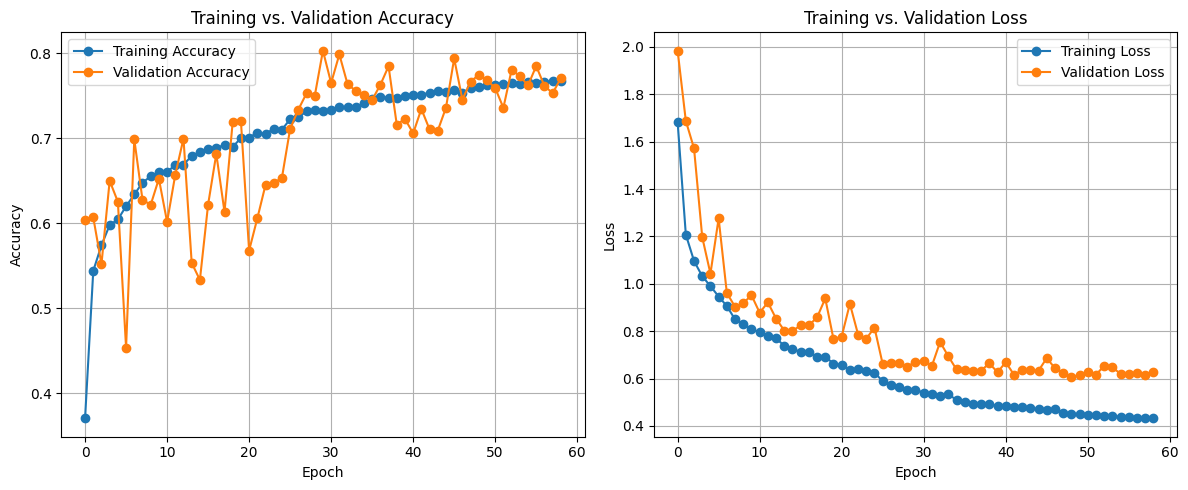

In [64]:
# -- Plot training history --

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [65]:
# -- Evaluate the model --

# Predict on test set
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=-1)

# Flatten for evaluation
y_true_flat = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

print("Accuracy:", accuracy_score(y_true_flat, y_pred_flat))
print(classification_report(y_true_flat, y_pred_flat))

50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 394ms/step
Accuracy: 0.774542236328125
              precision    recall  f1-score   support

           0       0.41      0.61      0.49     38146
           1       0.98      0.73      0.83    993424
           2       0.06      0.61      0.11     25366
           3       0.50      0.77      0.60     52486
           4       0.93      0.90      0.91    167285
           5       0.94      0.89      0.91    342076
           6       0.21      0.85      0.34      1592
           7       0.57      0.82      0.68     18025

    accuracy                           0.77   1638400
   macro avg       0.58      0.77      0.61   1638400
weighted avg       0.92      0.77      0.83   1638400



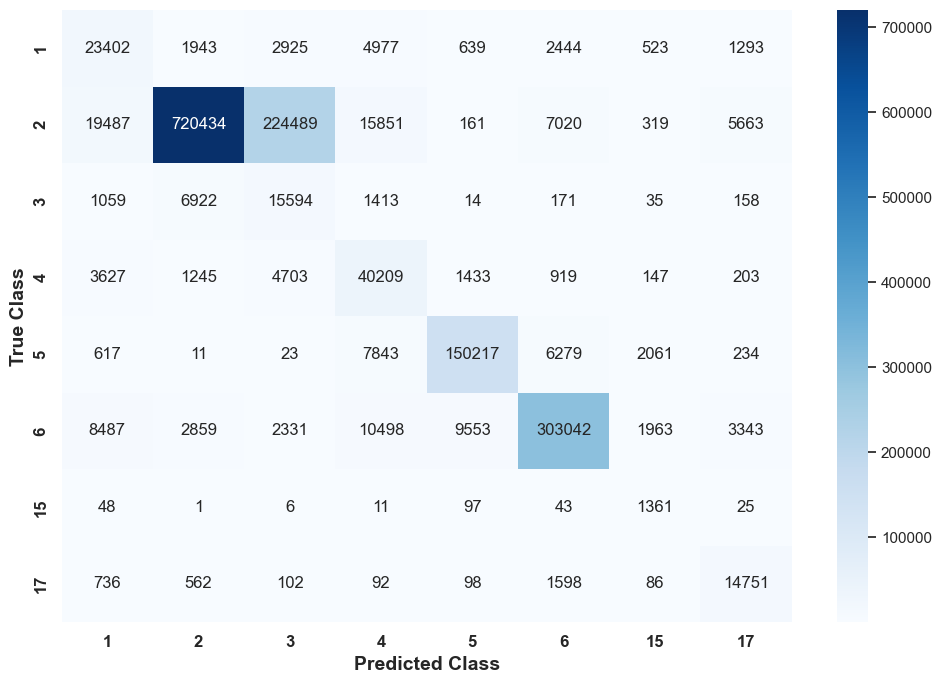

In [145]:
# Flatten labels
y_pred_flat = y_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true_flat, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels],)
# plt.title("Confusion Matrix")
plt.xlabel("Predicted Class", fontsize=14, fontweight='bold')
plt.ylabel("True Class", fontsize=14, fontweight='bold')
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Model deployment

In this section the trained model is deployed on the prepared, clipped laz-files of the five most populated municipalities of canton Zurich. The goal is to test how well the model performs on new, unseen data and then calculate the proportion of vegetation per municipality.

In [ ]:
# -- Functions for loading and evaluating city data --

def load_city_points(
    municipality_name: str,
    base_folder: str,
    N_POINTS: int,
    scaler,
    label_map: dict
):
    """
    Loads all points from a city, pads them to N_POINTS,
    and scales the non-spatial features.
    Args:
        municipality_name: Name of the city.
        base_folder: Base folder containing the .laz files.
        N_POINTS: Number of points per block.
        scaler: Scaler for non-spatial features.
        label_map: Mapping from raw labels to indices.
    Returns:
        X_blocks: Array of blocks of point cloud features.
        y_blocks: Array of blocks of point cloud labels.
        lengths: Array of lengths of each block.
    """
    city_folder = os.path.join(base_folder, municipality_name)
    paths = sorted(glob.glob(os.path.join(city_folder, "*.laz")))
    if not paths:
        raise RuntimeError(f"No .laz under {city_folder}")

    # Read all files
    all_feats  = []
    all_labels = []
    for p in paths:                                 
        las = laspy.read(p)
        ground = las.z.min()
        feats  = np.vstack([
            las.x, las.y, las.z,
            las.intensity,
            las.return_number,
            las.number_of_returns,
            las.z - ground,
            las.scan_angle
        ]).T.astype(np.float32)
        raw_lab = las.classification.astype(int)

        mask = raw_lab != 7
        feats = feats[mask]
        labs  = raw_lab[mask]
        labs  = np.array([label_map[c] for c in labs], dtype=np.int32)

        all_feats .append(feats)
        all_labels.append(labs)

    # Concatenate all files
    feats = np.concatenate(all_feats,  axis=0)
    labs  = np.concatenate(all_labels, axis=0)
    n_pts = feats.shape[0]

    n_blocks = int(np.ceil(n_pts / N_POINTS))
    pad      = n_blocks * N_POINTS - n_pts

    # Print points found
    print(f"{municipality_name}: {n_pts:,} points → {n_blocks} blocks of {N_POINTS}")

    # Pad the last chunk
    feats_pad = np.vstack([
        feats,
        np.repeat(feats[[-1], :], pad, axis=0)
    ])
    labs_pad  = np.concatenate([
        labs,
        np.repeat(labs[[-1]], pad)
    ])

    X_blocks = feats_pad.reshape(n_blocks, N_POINTS, -1)
    y_blocks = labs_pad.reshape(n_blocks, N_POINTS)

    # Center and scale each block
    for b in range(n_blocks):
        ctr = X_blocks[b, :, :3].mean(axis=0)
        X_blocks[b, :, :3] -= ctr

    M, P, F = X_blocks.shape
    flat     = X_blocks[:, :, 3:].reshape(-1, F-3)
    flat_sc  = scaler.transform(flat)
    X_blocks[:, :, 3:] = flat_sc.reshape(M, P, F-3)

    lengths = np.full(n_blocks, N_POINTS, dtype=int)
    lengths[-1] = N_POINTS - pad

    return X_blocks, y_blocks, lengths


def evaluate_city_full(
    municipality_name: str,
    base_folder: str,
    N_POINTS: int,
    scaler,
    label_map: dict,
    model
) -> pd.DataFrame:
    """
    - loads and blocks the city
    - runs inference on every block
    - stitches back to get y_true, y_pred for ALL points
    - prints metrics + confusion matrix
    - computes and returns vegetation proportions DataFrame
    Args:
        municipality_name: Name of the city.
        base_folder: Base folder containing the .laz files.
        N_POINTS: Number of points per block.
        scaler: Scaler for non-spatial features.
        label_map: Mapping from raw labels to indices.
        model: Trained Keras model.
    Returns:
        
    """
    Xb, yb, lengths = load_city_points(
        municipality_name, base_folder,
        N_POINTS, scaler, label_map
    )

    # Predict on all blocks
    prob = model.predict(Xb, verbose=0)
    pred = np.argmax(prob, axis=-1)

    # Discard padding and flatten
    true_flat, pred_flat = [], []
    for i, L in enumerate(lengths):
        true_flat.append(yb[i, :L])
        pred_flat.append(pred[i, :L])
    y_true = np.concatenate(true_flat)
    y_pred = np.concatenate(pred_flat)

    # Report
    print(f"\n=== {municipality_name} — {len(y_true):,} total points classified ===")
    acc = accuracy_score(y_true, y_pred)
    print(f"Accuracy: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, digits=4))

    # Confusion matrix
    inv_map = {v: k for k, v in label_map.items()}
    labels  = sorted(inv_map.keys())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(10,7))
    sns.heatmap(
      cm, annot=True, fmt="d", cmap="Blues",
      xticklabels=[inv_map[i] for i in labels],
      yticklabels=[inv_map[i] for i in labels]
    )
    # plt.title(f"Confusion Matrix – {municipality_name}") # not title for report
    plt.xlabel("Predicted Class", fontsize=14, fontweight='bold')
    plt.ylabel("True Class", fontsize=14, fontweight='bold')
    plt.xticks(fontsize=12, fontweight='bold')
    plt.yticks(fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Compute vegetation proportions
    veg_codes      = {3: "Low", 4: "Medium", 5: "High"}
    inv_map        = {v:k for k,v in label_map.items()}
    veg_idxs       = [label_map[c] for c in veg_codes]
    total_all      = len(y_true)

    # totals for truth‐veg vs pred‐veg
    total_true_veg = np.isin(y_true, veg_idxs).sum()
    total_pred_veg = np.isin(y_pred, veg_idxs).sum()

    rows = []
    for raw_code, name in veg_codes.items():
        idx            = label_map[raw_code]
        cnt_true_all   = (y_true == idx).sum()
        cnt_pred_all   = (y_pred == idx).sum()
        rows.append({
            "class":            name,
            "true_frac_of_all": cnt_true_all  / total_all,
            "pred_frac_of_all": cnt_pred_all  / total_all,
            "true_frac_of_veg": cnt_true_all  / total_true_veg,
            "pred_frac_of_veg": cnt_pred_all  / total_pred_veg,   
        })

    df_props = pd.DataFrame(rows).set_index("class")
    print("\nVegetation cover proportions:")
    display(df_props)

    return df_props

### Deploy above functions on the municipalities

#### Zürich

Zürich: 384,433,388 points → 375424 blocks of 1024

=== Zürich — 384,433,388 total points classified ===
Accuracy: 0.7522

              precision    recall  f1-score   support

           0     0.2197    0.3993    0.2835   9793184
           1     0.8961    0.7936    0.8417 197076571
           2     0.0535    0.3371    0.0923   5195334
           3     0.3375    0.5990    0.4317   8001718
           4     0.8118    0.7944    0.8030  27342252
           5     0.8663    0.7568    0.8079 132203299
           6     0.1392    0.4488    0.2124    463142
           7     0.2261    0.0728    0.1102   4357888

    accuracy                         0.7522 384433388
   macro avg     0.4438    0.5252    0.4478 384433388
weighted avg     0.8311    0.7522    0.7854 384433388



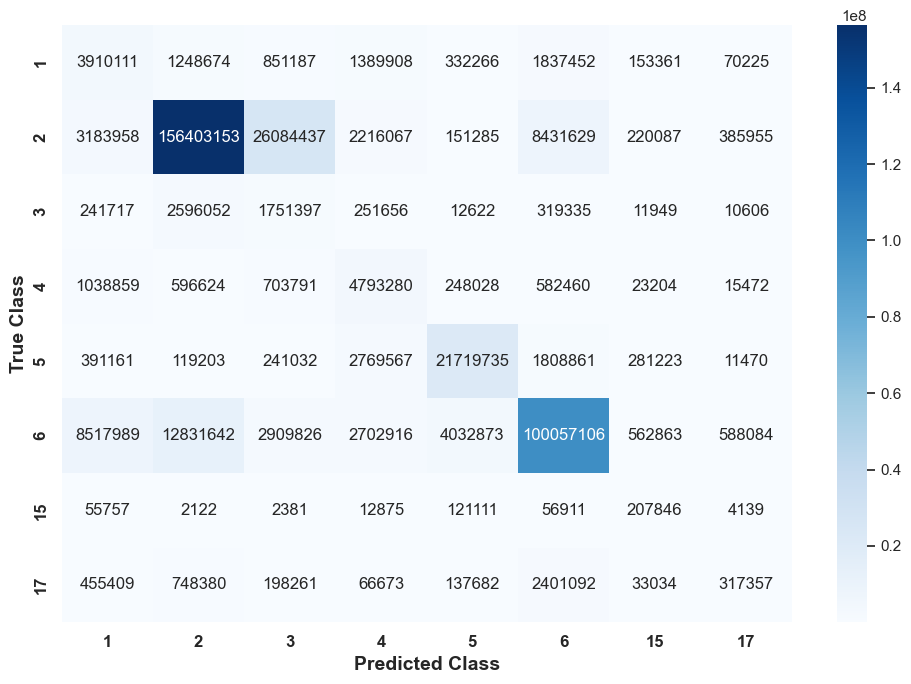


Vegetation cover proportions:


,true_frac_of_all,pred_frac_of_all,true_frac_of_veg,pred_frac_of_veg
class,,,,
Low,0.013514,0.085170,0.128155,0.444260
Medium,0.020814,0.036945,0.197382,0.192711
High,0.071124,0.069597,0.674463,0.363030


In [148]:
df_zurich = evaluate_city_full(
  municipality_name="Zürich",
  base_folder="C:/Users/flori/Desktop/pa-1_data/clipped_files",
  N_POINTS=1024,
  scaler=scaler,
  label_map=label_map,
  model=model
)

#### Winterthur

Winterthur: 138,200,473 points → 134962 blocks of 1024

=== Winterthur — 138,200,473 total points classified ===
Accuracy: 0.8023

              precision    recall  f1-score   support

           0     0.3030    0.3745    0.3350   3832237
           1     0.9200    0.8228    0.8687  72704363
           2     0.0582    0.3686    0.1005   1570343
           3     0.3807    0.6459    0.4791   2347968
           4     0.8533    0.8479    0.8506  10195729
           5     0.8904    0.8263    0.8572  46951383
           6     0.1722    0.3754    0.2361    180540
           7     0.0280    0.0277    0.0279    417910

    accuracy                         0.8023 138200473
   macro avg     0.4507    0.5361    0.4694 138200473
weighted avg     0.8652    0.8023    0.8299 138200473



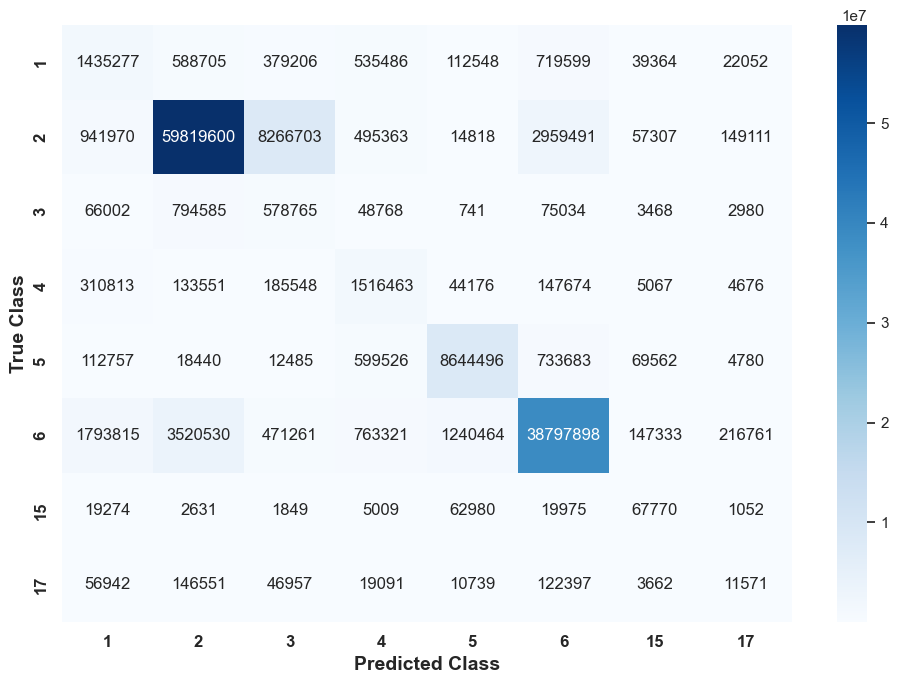


Vegetation cover proportions:


,true_frac_of_all,pred_frac_of_all,true_frac_of_veg,pred_frac_of_veg
class,,,,
Low,0.011363,0.071945,0.111261,0.413305
Medium,0.016990,0.028821,0.166357,0.165568
High,0.073775,0.073306,0.722382,0.421127


In [149]:
df_winterthur = evaluate_city_full(
  municipality_name="Winterthur",
  base_folder="C:/Users/flori/Desktop/pa-1_data/clipped_files",
  N_POINTS=1024,
  scaler=scaler,
  label_map=label_map,
  model=model
)

#### Uster

Uster: 35,163,378 points → 34340 blocks of 1024

=== Uster — 35,163,378 total points classified ===
Accuracy: 0.7696

              precision    recall  f1-score   support

           0     0.2147    0.4021    0.2799    733850
           1     0.9373    0.7939    0.8597  19576073
           2     0.0601    0.4162    0.1050    507426
           3     0.4239    0.6424    0.5108   1179620
           4     0.8595    0.7986    0.8279   3103535
           5     0.8784    0.7792    0.8258   9974364
           6     0.0297    0.3085    0.0542     11438
           7     0.0598    0.0422    0.0495     77072

    accuracy                         0.7696  35163378
   macro avg     0.4329    0.5229    0.4391  35163378
weighted avg     0.8665    0.7696    0.8105  35163378



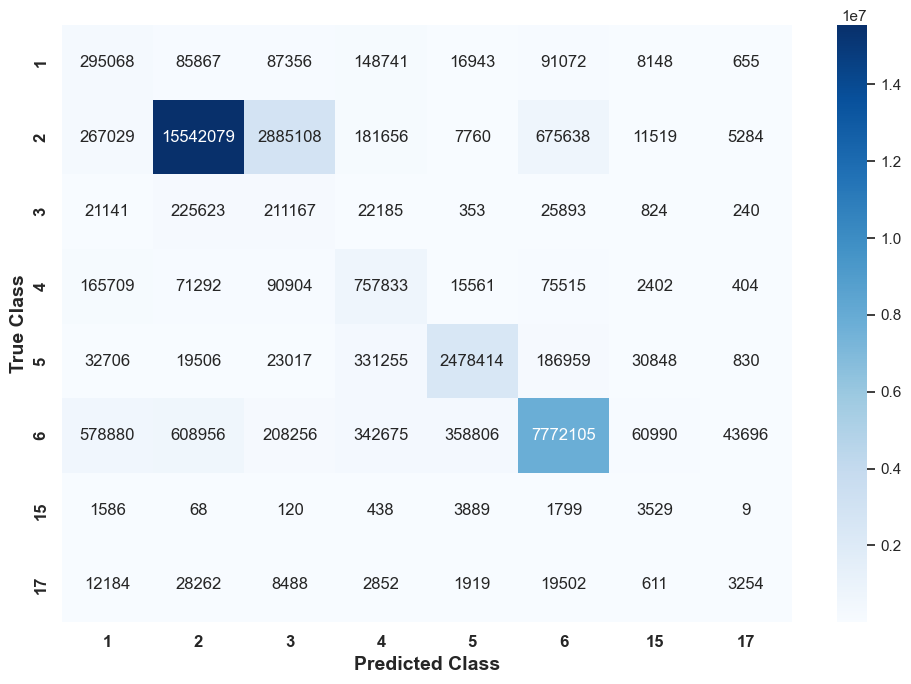


Vegetation cover proportions:


,true_frac_of_all,pred_frac_of_all,true_frac_of_veg,pred_frac_of_veg
class,,,,
Low,0.014431,0.099945,0.105922,0.429336
Medium,0.033547,0.050838,0.246237,0.218385
High,0.088260,0.082007,0.647841,0.352279


In [147]:
df_uster = evaluate_city_full(
  municipality_name="Uster",
  base_folder="C:/Users/flori/Desktop/pa-1_data/clipped_files",
  N_POINTS=1024,
  scaler=scaler,
  label_map=label_map,
  model=model
)

#### Dübendorf

Dübendorf: 36,071,947 points → 35227 blocks of 1024

=== Dübendorf — 36,071,947 total points classified ===
Accuracy: 0.7918

              precision    recall  f1-score   support

           0     0.1778    0.3133    0.2269    749177
           1     0.9475    0.8198    0.8790  22650533
           2     0.0490    0.2739    0.0832    469836
           3     0.4263    0.7000    0.5299    783471
           4     0.8265    0.8781    0.8515   1898176
           5     0.8219    0.8189    0.8204   8998190
           6     0.0408    0.2434    0.0699     13186
           7     0.2377    0.0854    0.1256    509378

    accuracy                         0.7918  36071947
   macro avg     0.4409    0.5166    0.4483  36071947
weighted avg     0.8604    0.7918    0.8205  36071947



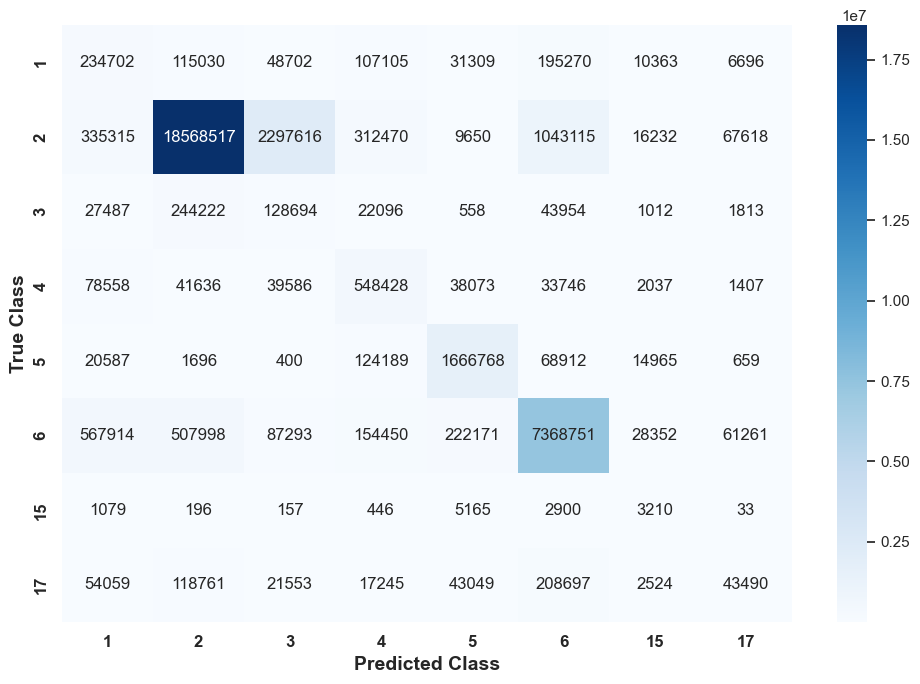


Vegetation cover proportions:


,true_frac_of_all,pred_frac_of_all,true_frac_of_veg,pred_frac_of_veg
class,,,,
Low,0.013025,0.072744,0.149084,0.442707
Medium,0.021720,0.035663,0.248604,0.217039
High,0.052622,0.055909,0.602312,0.340254


In [150]:
df_duebendorf = evaluate_city_full(
  municipality_name="Dübendorf",
  base_folder="C:/Users/flori/Desktop/pa-1_data/clipped_files",
  N_POINTS=1024,
  scaler=scaler,
  label_map=label_map,
  model=model
)

#### Dietikon

Dietikon: 53,595,845 points → 52340 blocks of 1024

=== Dietikon — 53,595,845 total points classified ===
Accuracy: 0.7460

              precision    recall  f1-score   support

           0     0.3273    0.5131    0.3996   1503355
           1     0.8856    0.8110    0.8467  33301890
           2     0.0468    0.3785    0.0833    745758
           3     0.3179    0.5594    0.4054   1045586
           4     0.7718    0.7021    0.7353   1905905
           5     0.9103    0.6717    0.7730  14815412
           6     0.3734    0.4330    0.4010     89933
           7     0.0421    0.0213    0.0283    188006

    accuracy                         0.7460  53595845
   macro avg     0.4594    0.5113    0.4591  53595845
weighted avg     0.8461    0.7460    0.7870  53595845



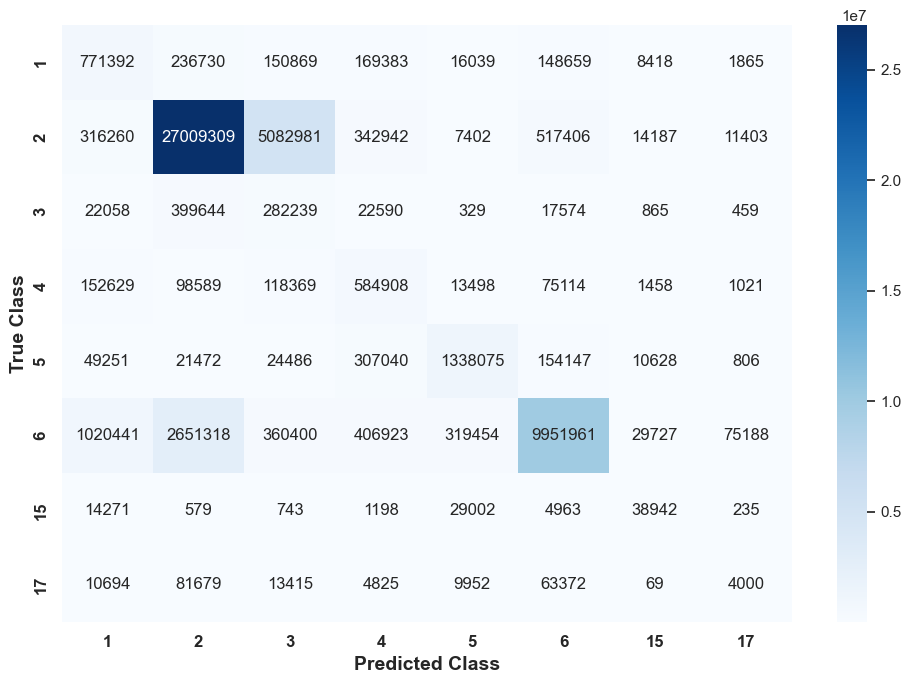


Vegetation cover proportions:


,true_frac_of_all,pred_frac_of_all,true_frac_of_veg,pred_frac_of_veg
class,,,,
Low,0.013914,0.112574,0.201706,0.628028
Medium,0.019509,0.034327,0.282801,0.191506
High,0.035561,0.032349,0.515493,0.180466


In [151]:
df_dietikon = evaluate_city_full(
  municipality_name="Dietikon",
  base_folder="C:/Users/flori/Desktop/pa-1_data/clipped_files",
  N_POINTS=1024,
  scaler=scaler,
  label_map=label_map,
  model=model
)

#### Copmare the evaluated municipalities

In [152]:
dfs = [
    ("Zürich",     df_zurich),
    ("Winterthur", df_winterthur),
    ("Uster",      df_uster),
    ("Dübendorf",  df_duebendorf),
    ("Dietikon",   df_dietikon)
]

tagged = []
for name, df in dfs:
    tmp = (
        df
        .reset_index()                     # moves index ["Low","Medium","High"] → column "index"
        .rename(columns={"index":"vegetation"})
    )
    tmp["municipality"] = name
    tagged.append(tmp)

# 3) Concatenate into one “long” DataFrame
big = pd.concat(tagged, ignore_index=True)

display(big)

,class,true_frac_of_all,pred_frac_of_all,true_frac_of_veg,pred_frac_of_veg,municipality
0,Low,0.013514,0.085170,0.128155,0.444260,Zürich
1,Medium,0.020814,0.036945,0.197382,0.192711,Zürich
2,High,0.071124,0.069597,0.674463,0.363030,Zürich
3,Low,0.011363,0.071945,0.111261,0.413305,Winterthur
4,Medium,0.016990,0.028821,0.166357,0.165568,Winterthur
5,High,0.073775,0.073306,0.722382,0.421127,Winterthur
6,Low,0.014431,0.099945,0.105922,0.429336,Uster
7,Medium,0.033547,0.050838,0.246237,0.218385,Uster
8,High,0.088260,0.082007,0.647841,0.352279,Uster
9,Low,0.013025,0.072744,0.149084,0.442707,Dübendorf


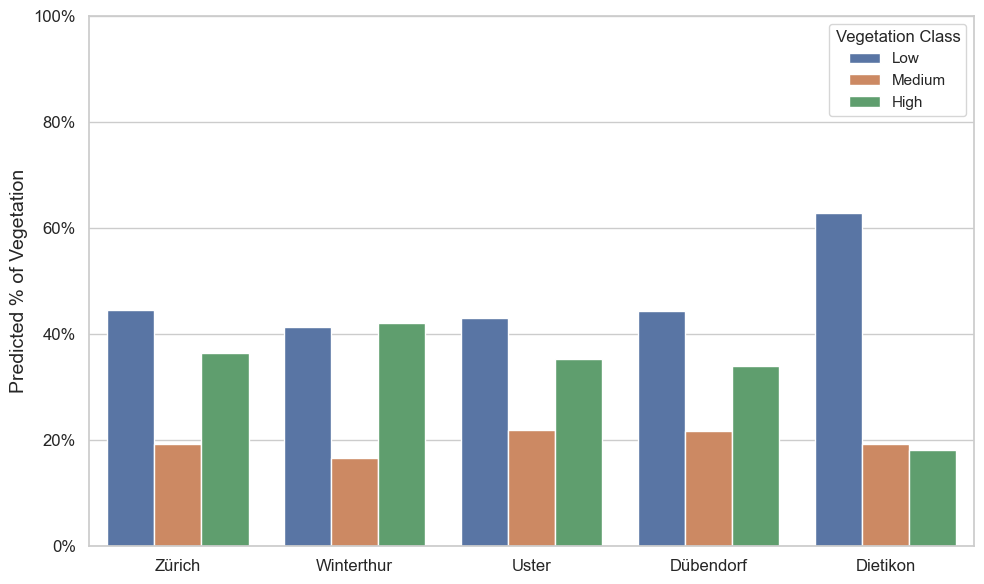

In [153]:
sns.set_theme(style="whitegrid")
town_order = ["Zürich","Winterthur","Uster","Dübendorf","Dietikon"]

# 1) -- Class breakdown (predicted only)
plt.figure(figsize=(10,6))
ax = sns.barplot(
    data=big,
    x="municipality",
    y="pred_frac_of_veg",
    hue="class",
    hue_order=["Low","Medium","High"],
    order=town_order,
    palette="deep",
    edgecolor="white"
)
ax.set_ylabel("Predicted % of Vegetation", fontsize=14)
ax.set_xlabel("")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
# ax.set_title("Predicted vegetation mix by municipality", fontsize=14, pad=15) # without title for report
plt.legend(title="Vegetation Class", fontsize=11, title_fontsize=12, loc="upper right")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

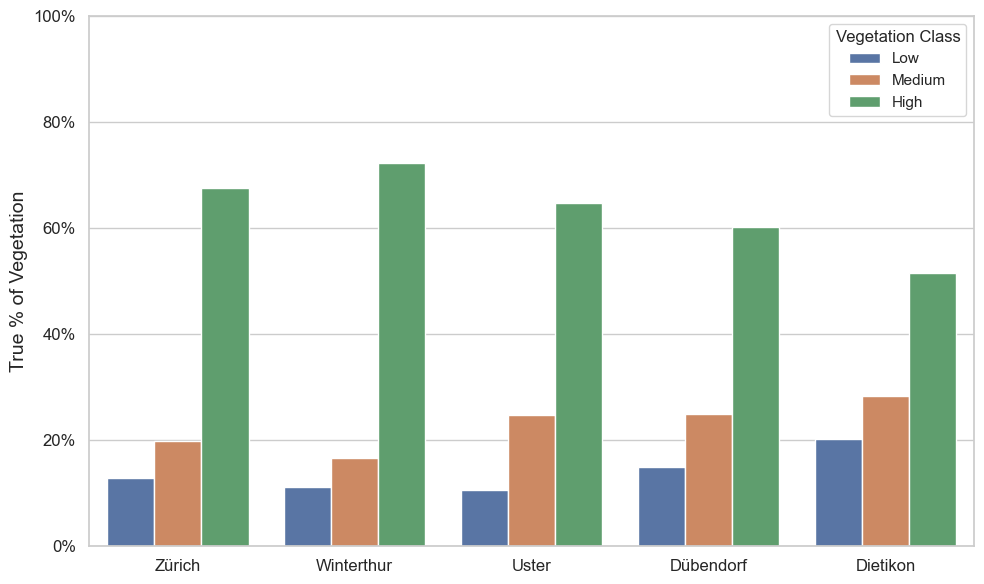

In [154]:
sns.set_theme(style="whitegrid")
town_order = ["Zürich","Winterthur","Uster","Dübendorf","Dietikon"]

# 1) -- Class breakdown (predicted only)
plt.figure(figsize=(10,6))
ax = sns.barplot(
    data=big,
    x="municipality",
    y="true_frac_of_veg",
    hue="class",
    hue_order=["Low","Medium","High"],
    order=town_order,
    palette="deep",
    edgecolor="white"
)
ax.set_ylabel("True % of Vegetation", fontsize=14)
ax.set_xlabel("")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
# ax.set_title("True vegetation mix by municipality", fontsize=14, pad=15) # without title for report
plt.legend(title="Vegetation Class", fontsize=11, title_fontsize=12, loc="upper right")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


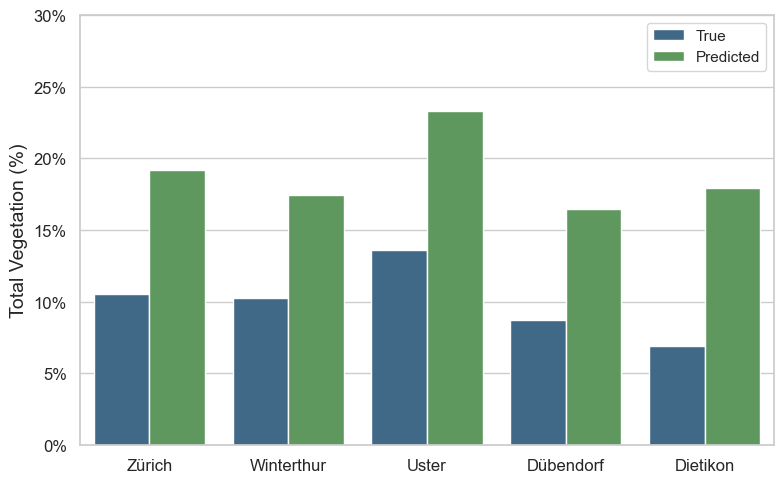

In [159]:
# -- Total vegetation fraction --
# compute per-town sums of low+med+high as % of all points
tot = big.groupby("municipality").agg(
    true_veg = ("true_frac_of_all","sum"),
    pred_veg = ("pred_frac_of_all","sum")
).reindex(town_order)

# melt for seaborn
tot = tot.reset_index().melt(
    id_vars="municipality",
    value_vars=["true_veg","pred_veg"],
    var_name="source",
    value_name="fraction"
)
tot["source"] = tot["source"].map({
    "true_veg": "True",
    "pred_veg": "Predicted"
})

plt.figure(figsize=(8,5))
ax = sns.barplot(
    data=tot,
    x="municipality",
    y="fraction",
    hue="source",
    order=town_order,
    palette=["#346b9398", "#54a254c6"],  # blue for True, green for Predicted
    edgecolor="white"
)
ax.set_ylabel("Total Vegetation (%)", fontsize=14)
ax.set_xlabel("") 
ax.set_ylim(0, 0.3)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
# ax.set_title("Overall Vegetation Cover by Municipality", fontsize=14, pad=15)

plt.legend(title="", fontsize=11, loc="upper right")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()
